In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
)

In [2]:
PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
X_test = pd.read_csv(PROCESSED_DIR / "X_test_raw_baseline.csv")

y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (13634, 11)
y_test: (13634,)


In [4]:
logistic_tuned = joblib.load(MODELS_DIR / "logistic_regression_tuned.joblib")

hist_tuned = joblib.load(MODELS_DIR / "histgradientboosting_tuned.joblib")

In [5]:
models = {
    "Logistic Regression Tuned": logistic_tuned,
    "HistGradientBoosting Tuned": hist_tuned,
}

In [6]:
predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob,
    }

In [7]:
results = []

for name, prediction in predictions.items():

    y_pred = prediction["y_pred"]
    y_prob = prediction["y_prob"]

    results.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
            "roc_auc": roc_auc_score(y_test, y_prob),
            "pr_auc": average_precision_score(y_test, y_prob),
        }
    )

final_results = pd.DataFrame(results)

In [8]:
final_results.round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression Tuned,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736
1,HistGradientBoosting Tuned,0.7373,0.7553,0.6923,0.7224,0.8040,0.7854


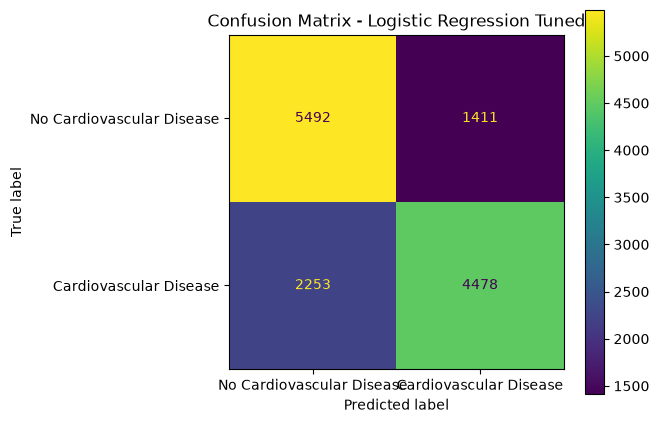

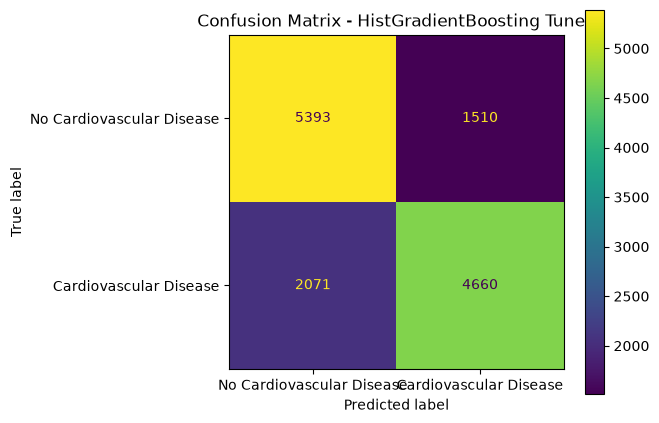

In [9]:
for name, prediction in predictions.items():

    cm = confusion_matrix(y_test, prediction["y_pred"])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Cardiovascular Disease", "Cardiovascular Disease"],
    )

    disp.plot()

    plt.title(f"Confusion Matrix - {name}")

    plt.tight_layout()
    plt.show()

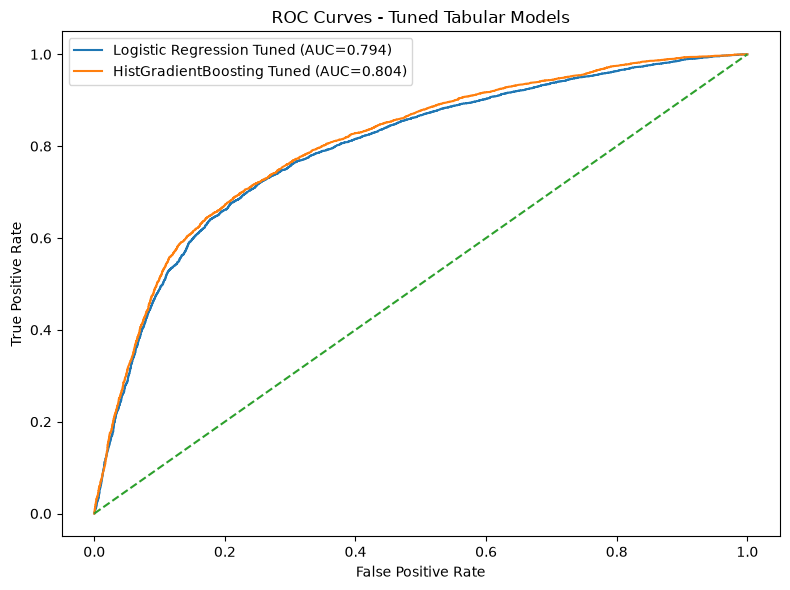

In [10]:
plt.figure(figsize=(8, 6))

for name, prediction in predictions.items():

    fpr, tpr, _ = roc_curve(y_test, prediction["y_prob"])

    auc = roc_auc_score(y_test, prediction["y_prob"])

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves - Tuned Tabular Models")

plt.legend()
plt.tight_layout()
plt.show()

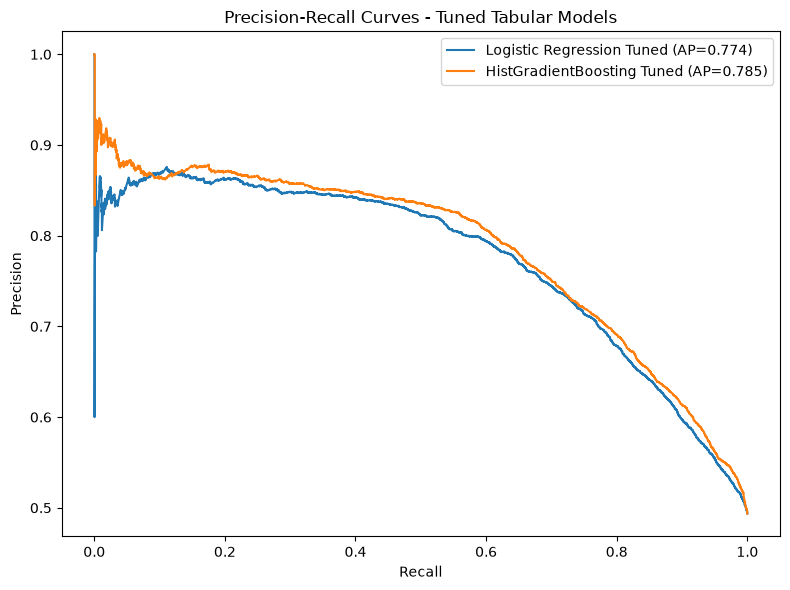

In [11]:
plt.figure(figsize=(8, 6))

for name, prediction in predictions.items():

    precision, recall, _ = precision_recall_curve(y_test, prediction["y_prob"])

    ap = average_precision_score(y_test, prediction["y_prob"])

    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curves - Tuned Tabular Models")

plt.legend()
plt.tight_layout()
plt.show()

In [12]:
untuned_results = pd.read_csv(REPORTS_DIR / "tabular_model_test_comparison.csv")

untuned_results

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.731260,0.760401,0.665280,0.709667,0.793824,0.773638
1,Random Forest,0.712410,0.710329,0.704947,0.707628,0.766869,0.744146
2,HistGradientBoosting,0.736688,0.753429,0.693656,0.722308,0.803797,0.784888


In [13]:
tuned_comparison = final_results.copy()

tuned_comparison["model"] = tuned_comparison["model"].str.replace(
    " Tuned", "", regex=False
)

tuned_comparison["version"] = "Tuned"

untuned_comparison = untuned_results.copy()
untuned_comparison["version"] = "Untuned"

combined_results = pd.concat([untuned_comparison, tuned_comparison], ignore_index=True)

combined_results.round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,version
0,Logistic Regression,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736,Untuned
1,Random Forest,0.7124,0.7103,0.7049,0.7076,0.7669,0.7441,Untuned
2,HistGradientBoosting,0.7367,0.7534,0.6937,0.7223,0.8038,0.7849,Untuned
3,Logistic Regression,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736,Tuned
4,HistGradientBoosting,0.7373,0.7553,0.6923,0.7224,0.8040,0.7854,Tuned


In [14]:
final_results.to_csv(REPORTS_DIR / "tabular_final_results.csv", index=False)

combined_results.to_csv(REPORTS_DIR / "tabular_untuned_vs_tuned.csv", index=False)

In [15]:
for name, prediction in predictions.items():

    filename = name.lower().replace(" ", "_")

    prediction_df = pd.DataFrame(
        {
            "y_true": y_test.to_numpy(),
            "y_pred": prediction["y_pred"],
            "y_probability": prediction["y_prob"],
        }
    )

    prediction_df.to_csv(REPORTS_DIR / f"{filename}_predictions.csv", index=False)

In [16]:
summary = {"models": final_results.to_dict(orient="records")}

with open(REPORTS_DIR / "tabular_final_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

In [17]:
print("FINAL TABULAR MODEL EVALUATION")
print("=" * 50)

display(final_results.round(4))

print("\nUntuned vs Tuned")
print("=" * 50)

display(combined_results.round(4))

FINAL TABULAR MODEL EVALUATION


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression Tuned,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736
1,HistGradientBoosting Tuned,0.7373,0.7553,0.6923,0.7224,0.8040,0.7854



Untuned vs Tuned


,model,accuracy,precision,recall,f1,roc_auc,pr_auc,version
0,Logistic Regression,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736,Untuned
1,Random Forest,0.7124,0.7103,0.7049,0.7076,0.7669,0.7441,Untuned
2,HistGradientBoosting,0.7367,0.7534,0.6937,0.7223,0.8038,0.7849,Untuned
3,Logistic Regression,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736,Tuned
4,HistGradientBoosting,0.7373,0.7553,0.6923,0.7224,0.8040,0.7854,Tuned


<Figure size 800x600 with 0 Axes>

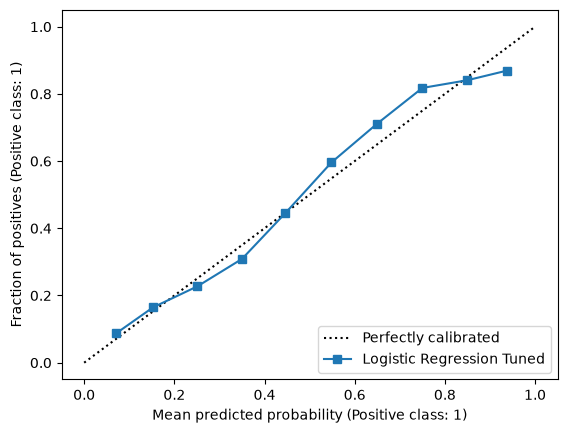

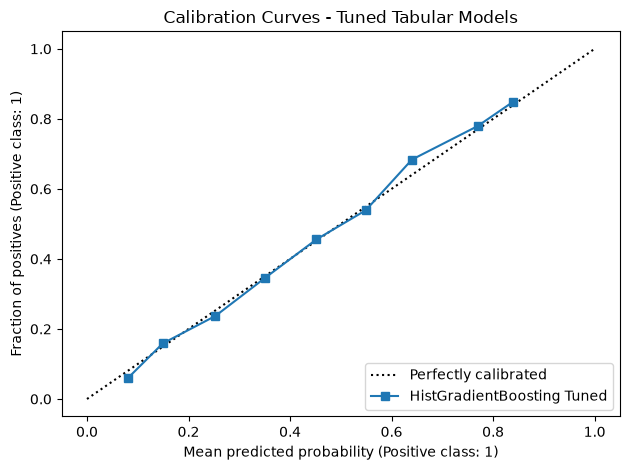

In [18]:
from sklearn.calibration import CalibrationDisplay

plt.figure(figsize=(8, 6))

for name, prediction in predictions.items():

    CalibrationDisplay.from_predictions(
        y_test,
        prediction["y_prob"],
        n_bins=10,
        name=name,
    )

plt.title("Calibration Curves - Tuned Tabular Models")
plt.tight_layout()
plt.show()

In [19]:
joblib.dump(hist_tuned, MODELS_DIR / "tabular_final_model.joblib")

['../models/tabular_final_model.joblib']

In [20]:
print("Saved:", MODELS_DIR / "tabular_final_model.joblib")

Saved: ../models/tabular_final_model.joblib
